In [1]:
!pip install lightning torch scikit-learn pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 17.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 34.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 44.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [lightning]


In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [4]:
from pathlib import Path
import os

PROJECT_DIR = Path(os.environ.get("RETAIL_PROJECT_DIR", Path.cwd())).resolve()
if not (PROJECT_DIR / "data").is_dir():
    PROJECT_DIR = next(
        (parent for parent in PROJECT_DIR.parents if (parent / "data").is_dir()),
        Path("/content/drive/MyDrive/Colab Notebooks/Retail Sales Prediction")
    )
DATA_DIR = PROJECT_DIR / "data"

file_path = (
    DATA_DIR / "daily_revenue.csv"
)

daily_revenue = pd.read_csv(
    file_path,
    index_col=0,
    parse_dates=True
).squeeze("columns")

daily_revenue = daily_revenue.sort_index()
daily_revenue = daily_revenue.astype(float).asfreq("D")

# Fill missing calendar dates, if any
daily_revenue = daily_revenue.interpolate(method="time")

print("Total observations:", len(daily_revenue))
print(daily_revenue.head())
print(daily_revenue.isna().sum())

Total observations: 374
InvoiceDate
2009-12-01    53173.03
2009-12-02    62763.59
2009-12-03    68093.05
2009-12-04    40346.40
2009-12-05     9803.05
Freq: D, Name: Revenue, dtype: float64
0


In [5]:
# Prepare sequences for the LSTM

from sklearn.preprocessing import MinMaxScaler

LOOKBACK = 28

values = daily_revenue.to_numpy().reshape(-1, 1)

# Split chronologically before fitting the scaler
split_index = int(len(values) * 0.8)

scaler = MinMaxScaler()
scaler.fit(values[:split_index])

scaled_values = scaler.transform(values)

def create_sequences(data, lookback):
    X, y, target_indices = [], [], []

    for i in range(lookback, len(data)):
        X.append(data[i - lookback:i])
        y.append(data[i, 0])
        target_indices.append(i)

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32),
        np.asarray(target_indices)
    )

X, y, target_indices = create_sequences(
    scaled_values, LOOKBACK
)

train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (271, 28, 1)
X_test: (75, 28, 1)


In [6]:
# Create the PyTorch Lightning LSTM model

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
import lightning.pytorch as pl

class RevenueLSTM(pl.LightningModule):

    def __init__(
        self,
        input_size=1,
        hidden_size=64,
        num_layers=2,
        learning_rate=0.001
    ):
        super().__init__()

        self.save_hyperparameters()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2 if num_layers > 1 else 0.0
        )

        self.fc = nn.Linear(hidden_size, 1)
        self.loss_fn = nn.MSELoss()

    def forward(self, x):
        output, _ = self.lstm(x)
        last_output = output[:, -1, :]
        return self.fc(last_output).squeeze(-1)

    def training_step(self, batch, batch_idx):
        x, y = batch
        predictions = self(x)
        loss = self.loss_fn(predictions, y)

        self.log(
            "train_loss",
            loss,
            on_epoch=True,
            prog_bar=True
        )
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        predictions = self(x)
        loss = self.loss_fn(predictions, y)

        self.log(
            "val_loss",
            loss,
            on_epoch=True,
            prog_bar=True
        )
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(
            self.parameters(),
            lr=self.hparams.learning_rate
        )

In [7]:
# Create DataLoaders and train the model

from lightning.pytorch.callbacks import EarlyStopping

# Reserve the last 10% of training sequences for validation
val_start = int(len(X_train) * 0.9)

X_fit, y_fit = X_train[:val_start], y_train[:val_start]
X_val, y_val = X_train[val_start:], y_train[val_start:]

train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_fit),
        torch.tensor(y_fit)
    ),
    batch_size=32,
    shuffle=False
)

val_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_val),
        torch.tensor(y_val)
    ),
    batch_size=32,
    shuffle=False
)

model = RevenueLSTM()

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    mode="min"
)

trainer = pl.Trainer(
    max_epochs=50,
    accelerator="auto",
    devices=1,
    callbacks=[early_stopping],
    log_every_n_steps=1,
    enable_checkpointing=True
)

trainer.fit(
    model,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader
)

INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch.utilities

┏━━━┳━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type    ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ lstm    │ LSTM    │ 50.4 K │ train │     0 │
│ 1 │ fc      │ Linear  │     65 │ train │     0 │
│ 2 │ loss_fn │ MSELoss │      0 │ train │     0 │
└───┴─────────┴─────────┴────────┴───────┴───────┘

Trainable params: 50.5 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 50.5 K                                                                                               
Total estimated model params size (MB): 0.202                                                                      
Modules in train mode: 3                                                                                           
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

In [8]:
# Evaluate the LSTM model

from sklearn.metrics import mean_absolute_error, mean_squared_error

model.eval()

with torch.no_grad():
    X_test_tensor = torch.tensor(X_test)
    predictions_scaled = model(X_test_tensor).cpu().numpy()

actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

predicted = scaler.inverse_transform(
    predictions_scaled.reshape(-1, 1)
).ravel()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print(f"LSTM MAE: {mae:,.2f}")
print(f"LSTM RMSE: {rmse:,.2f}")

LSTM MAE: 25,744.62
LSTM RMSE: 30,711.45


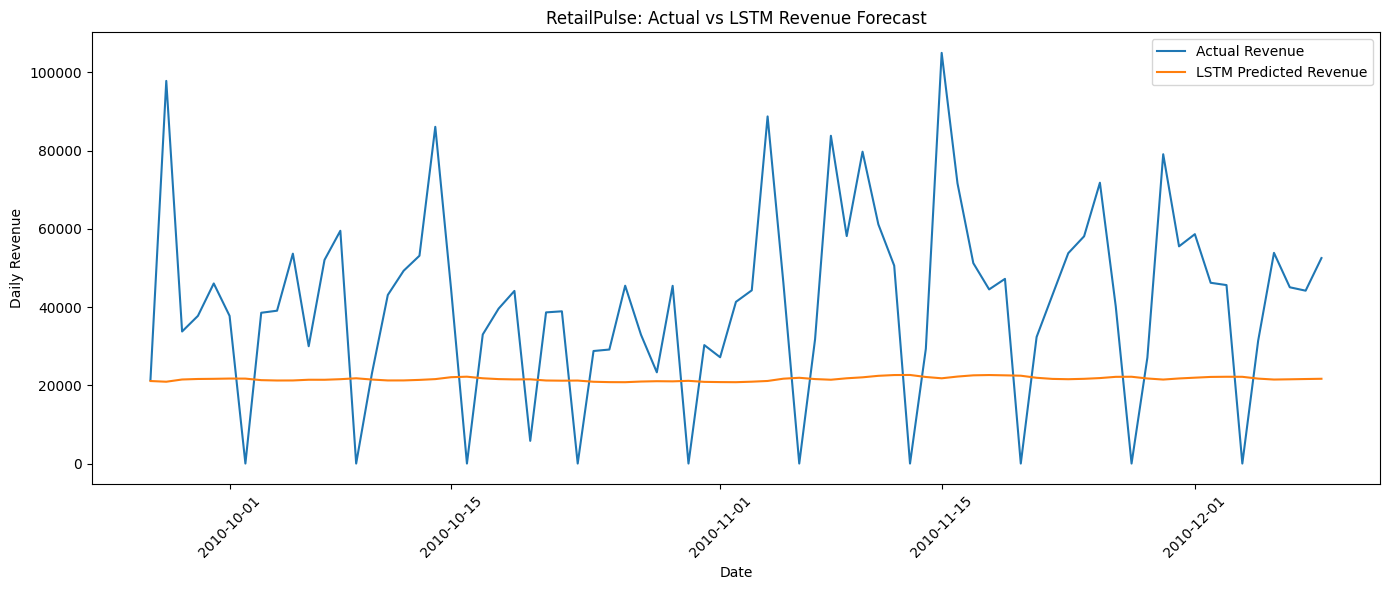

In [9]:
# Visualize actual versus predicted revenue

test_dates = daily_revenue.index[target_indices[test_mask]]

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    actual,
    label="Actual Revenue"
)

plt.plot(
    test_dates,
    predicted,
    label="LSTM Predicted Revenue"
)

plt.title("RetailPulse: Actual vs LSTM Revenue Forecast")
plt.xlabel("Date")
plt.ylabel("Daily Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
# Save the trained model

model_dir = str(PROJECT_DIR / "model")

os.makedirs(model_dir, exist_ok=True)

torch.save(
    model.state_dict(),
    os.path.join(model_dir, "lstm_revenue_model.pth")
)

import joblib

joblib.dump(
    scaler,
    os.path.join(model_dir, "revenue_scaler.pkl")
)

print("LSTM model and scaler saved successfully.")

LSTM model and scaler saved successfully.


# **Hybrid Forecasting Model: Prophet + LSTM Ensemble**

In [13]:
# Prepare the weekly data

# Resample daily revenue to weekly frequency ('W') and format for Prophet
weekly_revenue = daily_revenue.resample("W").sum().reset_index()
weekly_revenue.columns = ["ds", "y"]

weekly_revenue = (
    weekly_revenue.sort_values("ds")
    .reset_index(drop=True)
)

split_index = int(len(weekly_revenue) * 0.8)

train_weekly = weekly_revenue.iloc[:split_index].copy()
test_weekly = weekly_revenue.iloc[split_index:].copy()

print("Training rows:", len(train_weekly))
print("Testing rows:", len(test_weekly))

Training rows: 43
Testing rows: 11


In [14]:
!pip install -q lightning

In [15]:
# Train the LSTM model

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import lightning.pytorch as pl

LOOKBACK = 4

# Fit the scaler only on training revenue
scaler = MinMaxScaler()
train_values = scaler.fit_transform(
    train_weekly[["y"]]
).astype(np.float32)

# Transform test data using the same scaler
all_values = scaler.transform(
    weekly_revenue[["y"]]
).astype(np.float32)

def create_sequences(values, lookback):
    X, y = [], []

    for i in range(lookback, len(values)):
        X.append(values[i - lookback:i])
        y.append(values[i, 0])

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.float32)
    )

X_train, y_train = create_sequences(
    train_values, LOOKBACK
)

train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train),
        torch.tensor(y_train)
    ),
    batch_size=8,
    shuffle=False
)

class WeeklyLSTM(pl.LightningModule):
    def __init__(self, hidden_size=16, learning_rate=0.001):
        super().__init__()
        self.save_hyperparameters()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.output_layer = nn.Linear(hidden_size, 1)
        self.loss_fn = nn.MSELoss()

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.output_layer(
            output[:, -1, :]
        ).squeeze(-1)

    def training_step(self, batch, batch_idx):
        x, y = batch
        loss = self.loss_fn(self(x), y)
        self.log("train_loss", loss, prog_bar=True)
        return loss

    def configure_optimizers(self):
        return torch.optim.Adam(
            self.parameters(),
            lr=self.hparams.learning_rate
        )

pl.seed_everything(42, workers=True)

lstm_model = WeeklyLSTM()

trainer = pl.Trainer(
    max_epochs=100,
    accelerator="auto",
    devices=1,
    logger=False,
    enable_checkpointing=False,
    enable_model_summary=False
)

trainer.fit(lstm_model, train_dataloaders=train_loader)

INFO: Seed set to 42
INFO:lightning.fabric.utilities.seed:Seed set to 42
INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
INFO: `Trainer.fit` stopped: `max_epochs=100` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=100` reached.


In [18]:
# Generate LSTM and Prophet predictions

from prophet import Prophet

lstm_model.eval()

lstm_predictions_scaled = []

with torch.no_grad():
    for target_idx in range(split_index, len(weekly_revenue)):
        # Previous four weeks, including actual history
        sequence = all_values[
            target_idx - LOOKBACK:target_idx
        ]

        x = torch.tensor(sequence).unsqueeze(0)

        prediction = lstm_model(x).cpu().numpy()[0]

        lstm_predictions_scaled.append(prediction)

lstm_predictions = scaler.inverse_transform(
    np.array(lstm_predictions_scaled).reshape(-1, 1)
).ravel()

# Prophet v2 predictions on exactly the same test dates
prophet_model = Prophet(
    weekly_seasonality=False,
    yearly_seasonality=False,
    daily_seasonality=False,
    changepoint_prior_scale=0.001
)

prophet_model.fit(train_weekly)

prophet_forecast = prophet_model.predict(
    test_weekly[["ds"]]
)

prophet_predictions = prophet_forecast["yhat"].to_numpy()
actual = test_weekly["y"].to_numpy()

assert len(prophet_predictions) == len(lstm_predictions) == len(actual)

In [19]:
# Combine the predictions

prophet_weight = 0.5
lstm_weight = 0.5

hybrid_predictions = (
    prophet_weight * prophet_predictions
    + lstm_weight * lstm_predictions
)

results = pd.DataFrame({
    "ds": test_weekly["ds"].to_numpy(),
    "Actual": actual,
    "Prophet": prophet_predictions,
    "LSTM": lstm_predictions,
    "Hybrid": hybrid_predictions
})

display(results.head(10))

,ds,Actual,Prophet,LSTM,Hybrid
0,2010-10-03,291652.130,141391.965753,152437.281250,146914.623501
1,2010-10-10,257386.970,141236.721765,155501.625000,148369.173383
2,2010-10-17,309080.930,141081.477778,152001.484375,146541.481076
3,2010-10-24,195850.020,140926.233790,153392.000000,147159.116895
4,2010-10-31,206556.980,140770.989803,146107.140625,143439.065214
5,2010-11-07,279382.870,140615.745815,146622.203125,143618.974470
6,2010-11-14,362717.611,140460.501828,152008.031250,146234.266539
7,2010-11-21,351931.091,140305.257840,158373.203125,149339.230483
8,2010-11-28,294028.020,140150.013853,156114.609375,148132.311614
9,2010-12-05,316442.300,139994.769865,150172.859375,145083.814620


In [20]:
# Evaluate all models

def evaluate_forecast(actual, predicted, model_name):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    return {
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2)
    }

comparison = pd.DataFrame([
    evaluate_forecast(actual, prophet_predictions, "Prophet v2"),
    evaluate_forecast(actual, lstm_predictions, "LSTM"),
    evaluate_forecast(actual, hybrid_predictions, "Hybrid Prophet + LSTM")
])

display(comparison.sort_values("MAE").reset_index(drop=True))

,Model,MAE,RMSE
0,LSTM,126121.61,137535.11
1,Hybrid Prophet + LSTM,131874.30,143063.69
2,Prophet v2,137626.99,148631.11


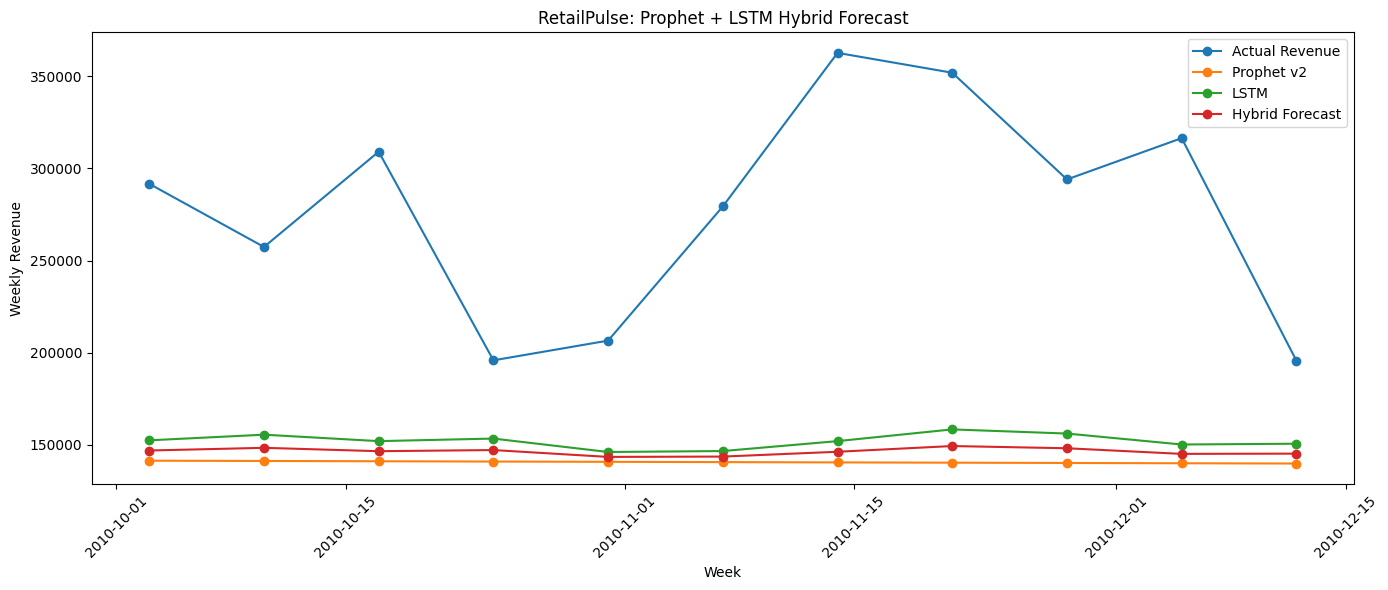

In [21]:
# Plot the hybrid forecast

plt.figure(figsize=(14, 6))

plt.plot(
    results["ds"], results["Actual"],
    marker="o", label="Actual Revenue"
)

plt.plot(
    results["ds"], results["Prophet"],
    marker="o", label="Prophet v2"
)

plt.plot(
    results["ds"], results["LSTM"],
    marker="o", label="LSTM"
)

plt.plot(
    results["ds"], results["Hybrid"],
    marker="o", label="Hybrid Forecast"
)

plt.title("RetailPulse: Prophet + LSTM Hybrid Forecast")
plt.xlabel("Week")
plt.ylabel("Weekly Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Key findings
- LSTM is the best of these three models. It achieved the lowest MAE and RMSE.
- The hybrid model did not outperform LSTM. Combining Prophet with LSTM increased MAE by 5,752.69 and RMSE by 5,528.58 compared with LSTM alone.
- LSTM outperformed Prophet v2. Its MAE was approximately 8.36% lower, and its RMSE was approximately 7.47% lower than Prophet v2.
- The equal-weight ensemble may be giving too much influence to Prophet, whose errors are higher than those of LSTM.

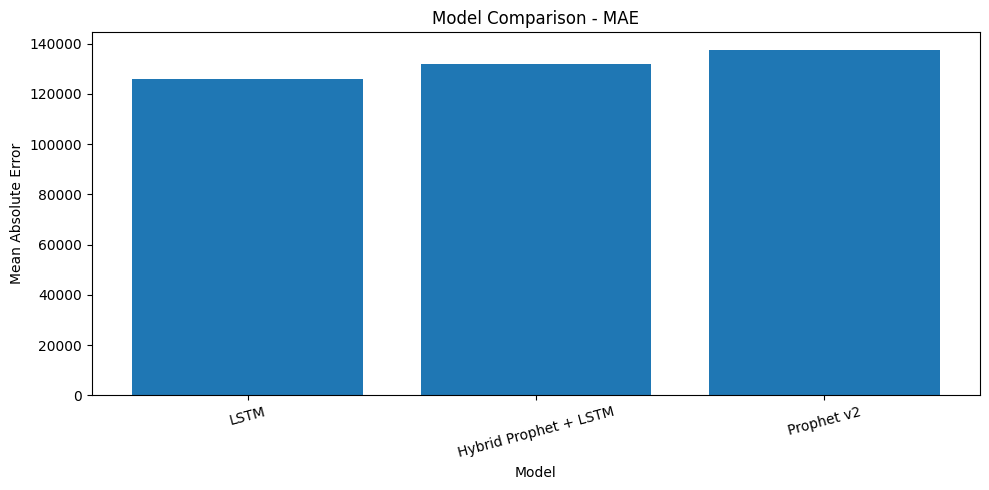

In [22]:
# Visualize the model comparison

comparison_sorted = comparison.sort_values("MAE")

plt.figure(figsize=(10, 5))
plt.bar(comparison_sorted["Model"], comparison_sorted["MAE"])

plt.title("Model Comparison - MAE")
plt.xlabel("Model")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [23]:
# tune the hybrid weights

weight_results = []

for prophet_weight in np.arange(0, 1.01, 0.1):
    lstm_weight = 1 - prophet_weight

    hybrid_pred = (
        prophet_weight * prophet_predictions
        + lstm_weight * lstm_predictions
    )

    weight_results.append({
        "Prophet Weight": round(prophet_weight, 1),
        "LSTM Weight": round(lstm_weight, 1),
        "MAE": mean_absolute_error(actual, hybrid_pred),
        "RMSE": np.sqrt(mean_squared_error(actual, hybrid_pred))
    })

weight_comparison = pd.DataFrame(weight_results)

display(
    weight_comparison.sort_values("MAE").reset_index(drop=True)
)

,Prophet Weight,LSTM Weight,MAE,RMSE
0,0.0,1.0,126121.614784,137535.108356
1,0.1,0.9,127272.152561,138637.495495
2,0.2,0.8,128422.690337,139741.586988
3,0.3,0.7,129573.228113,140847.342752
4,0.4,0.6,130723.765890,141954.723897
5,0.5,0.5,131874.303666,143063.692679
6,0.6,0.4,133024.841443,144174.212462
7,0.7,0.3,134175.379219,145286.247680
8,0.8,0.2,135325.916996,146399.763800
9,0.9,0.1,136476.454772,147514.727287


### Hybrid Forecasting Model: Prophet + LSTM Ensemble

**Objective:** Develop a hybrid time-series forecasting model by combining Prophet and LSTM to predict weekly retail revenue.

**Methodology:** Prophet was used to model trend and seasonal patterns, while LSTM was trained to learn sequential patterns in historical weekly revenue. Their predictions were combined using an equal-weight ensemble, with 50% weight assigned to each model.

**Evaluation metrics:** Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) were used to compare model performance on the test dataset.

**Results:**

| Model | MAE | RMSE |
|---|---:|---:|
| LSTM | 126,121.61 | 137,535.11 |
| Hybrid Prophet + LSTM | 131,874.30 | 143,063.69 |
| Prophet v2 | 137,626.99 | 148,631.11 |


**Conclusion:** Among the three evaluated models, LSTM achieved the lowest MAE and RMSE. The equal-weight hybrid ensemble improved upon Prophet v2 but did not outperform LSTM alone. Further experimentation with ensemble weights and validation-based model selection may improve performance. The naive baseline should also be retained as a benchmark because it previously achieved lower errors than these models.

**Limitation:** The weekly dataset contains a limited number of observations, which may affect the reliability and generalization of the LSTM and ensemble models.
